# Transport test, round 1: does a small fine-tune land on existing VPD subcomponents?

Results in `experiments/transport_test/results/`, figures in `experiments/transport_test/figures/`, scoring in `reports/analyses/2026-10-14_analysis_transport-test.md`. Run `python experiments/transport_test/plot.py` first if the figures are missing.

## Motivation

The project's question (`GOALS.md`) is whether there is a simple map Φ that takes a post-training update δW (e.g. a LoRA) and turns it into an update on the parameter components, so that the updated decomposition is faithful to the new model. A stronger version asks that it also be close to what re-decomposing the new model would give; that version is postponed. If such a Φ exists, the decomposition stays valid and readable along training ("these mechanisms got stronger, weaker or slightly changed").

Round 1 was designed before the question was stated this precisely. It tests one candidate Φ and two related questions:

- **One simple map:** project δW onto the existing subcomponents (T0 Frobenius). Measure 1 asks how much of δW, as a matrix, this captures.
- **Whether a sparse component update exists at all:** fit changes to a few subcomponents so that they reproduce the fine-tuned model's *behaviour* (measure 2). These are optimisations, not a simple map, but a good Φ requires that such an update exists.
- **Brittleness:** does the decomposition stay faithful when the weights move (measure 3)?

**Caveat (added after round 1).** Measure 3 recomputes the residual Δ as the new weights minus the components, so Δ absorbs whatever the components miss. The trivial map "change nothing, put δW in Δ" therefore passes it. Measure 3 shows the decomposition is not brittle, but it cannot score a candidate Φ. Round 2 holds Δ at its old value. Round 2 will also test the pull-back map (apply the training step to U and V instead of W) and LoRA updates (`backlog.md`).

## Notation

**Model and decomposition.**
- $f_W$ is Goodfire's 4-layer, 67M-parameter Pile transformer. $W = \{W_m\}$ are its 24 decomposed matrices: $m$ ranges over `h.ℓ.attn.{q,k,v,o}_proj` and `h.ℓ.mlp.{c_fc,down_proj}` for layers ℓ = 0..3. Each $W_m \in \mathbb{R}^{d_\text{out}\times d_\text{in}}$. $W_0$ is the released weights.
- The VPD decomposition (Goodfire's run `s-55ea3f9b`) writes each matrix as a sum of rank-1 **subcomponents** plus a residual: $W_m = \sum_c U_c V_c^\top + \Delta_m$. There are 38,912 subcomponents in all, written `matrix:index`, e.g. `h.2.mlp.down_proj:2359`.
- For an input $x$, a subcomponent contributes $U_c V_c^\top x = U_c\,(V_c\cdot x)$. $V_c \in \mathbb{R}^{d_\text{in}}$ is its **read vector**: the input direction it responds to. $U_c \in \mathbb{R}^{d_\text{out}}$ is its **write vector**: what it adds to the output.
- **Causal importance** $g_c \in [0,1]$ is computed per token by a small learned network Γ. It says how much the model needs subcomponent $c$ on that token.
- A subcomponent is **alive** if its mean $g_c$ over 256 Pile validation rows exceeds $10^{-6}$ (the paper's rule): 9,881 of 38,912. Δ is the residual the subcomponents do not cover.

**Fine-tunes.** We fine-tune only the 24 matrices. $\delta W = W_\text{ft} - W_0$, and $f_\text{ft} = f_{W_0+\delta W}$.

**Transports.** A transport $T$ changes subcomponents only, with Γ and Δ frozen. It gives weights $W_T$ and a model $f_T$. Everything is fitted per checkpoint.

| name | what may change | $W_T - W_0$ |
|---|---|---|
| null transport | nothing (δW is left in Δ) | — |
| T0 Frobenius | one scalar $\alpha_c$ per alive subcomponent, by least squares to δW in weight space | $\sum_{c\text{ alive}} \alpha_c U_c V_c^\top$ |
| T0 functional | the same scalars, optimised (Adam, 150 steps) to minimise $\mathrm{KL}(f_\text{ft}\,\|\,f_T)$ on the fine-tune's training data | same form |
| T1 write, k | a free change $\delta U_c$ to the write vector of each $c$ in a set $S$ of $k$ subcomponents | $\sum_{c\in S} \delta U_c V_c^\top$ |
| T1 read, k | a free change $\delta V_c$ to the read vector | $\sum_{c\in S} U_c\, \delta V_c^\top$ |
| random null, k | T1 write with $S$ drawn uniformly from the alive subcomponents, same count per matrix, 5 seeds | as T1 write |

For T1, $S$ is the top $k$ by **Frobenius contribution** $|\alpha_c|\,\|U_c\|\,\|V_c\|$, using the T0 Frobenius $\alpha$. This choice is the **selector**.

**Measures.**
1. **Frobenius fraction** (the projection map). Let $P_m$ be the orthogonal projection, in the Frobenius inner product, onto $\mathrm{span}\{U_c V_c^\top : c \text{ alive in } m\}$. The fraction is the share of the update's squared Frobenius norm that lies in that span: $\phi_m = \|P_m\,\delta W_m\|_F^2 / \|\delta W_m\|_F^2$, pooled over matrices as $\phi = \sum_m \|P_m \delta W_m\|_F^2 / \sum_m \|\delta W_m\|_F^2$. 1 means δW is a reweighting of alive subcomponents; 0 means it is orthogonal to all of them. **Baseline (arm N):** a Gaussian δW with the same per-matrix norm. Its expected fraction is the dimension ratio, $n_{\text{alive},m}/(d_\text{out} d_\text{in})$, about 0.035% pooled.
2. **Capture** (does a sparse component update exist?): $1 - \mathrm{KL}(f_\text{ft}\,\|\,f_T)\,/\,\mathrm{KL}(f_\text{ft}\,\|\,f_{W_0})$. Each KL is the next-token KL per position, averaged over held-out positions. Capture = 1 means the transport reproduces the fine-tuned model. Capture = 0 means it does no better than not updating at all. Capture < 0 means it does worse than that.
3. **Faithfulness ratio** (brittleness). The paper's stochastic-mask KL and adversarial-mask (PGD, 20 steps, one adversary per 128 rows) KL, computed for the transported decomposition at $W_0+\delta W$. Each is divided by the same metric for the released decomposition on $W_0$, using our own calibration on the same rows. A ratio near 1 means no loss of faithfulness.
4. **Location:** the rank of `h.2.mlp.down_proj:2359` and its five siblings by Frobenius contribution within their matrix.

## The arms, and why each

- **Arm A, emoticon → `o`** (the most favourable case). The VPD paper found that `h.2.mlp.down_proj:2359` is causally important at emoticon positions (` :` before `D`, `P`, `)`). Editing its write vector by hand makes the model predict `o` there. We do the same with a full-weight fine-tune instead of a hand edit: 365 training windows of 41 tokens centred where $g_{2359} > 0.5$, cross-entropy on `o` at the centre (index 20), and a KL penalty to $W_0$ on the other 40 positions. A one-subcomponent answer is known to exist here, so if the update does not commute in this case it is unlikely to commute anywhere.
- **Arm B, continued pretraining.** More Pile text at learning rate 1e-5. It teaches no new skill, so if commuting holds anywhere it should hold for this "strengthen what's there" update.
- **Arm N, random direction.** The null for measure 1.

## Predictions, filed before the run (`results/predictions.json`), and verdicts

| # | prediction | verdict |
|---|---|---|
| 1a | Arm A: T1 write k=10 capture ≥ 0.5 **and** ≥ 0.3 above the random null | reversed: 1.000 vs 0.987, a margin inside the null band (< 0.1) |
| 1b | Arm A: 2359 or a sibling in the top 5 of its matrix (not scored) | held: 2359 ranks 2nd at step 10 |
| 2 | Arm B: Frobenius fraction ≥ 10× arm N **and** T0 functional capture ≥ 0.5 | reversed: 1.5×, capture −0.09 |
| 3 | Faithfulness ratios ≤ 2 for the scored transports | held |
| 4 | Calibration on $W_0$ within 1.5× of the paper (gate, not scored) | held |

Reversal 1a does not show that the decomposition carries no information. It shows the null was expressive enough to mimic the behaviour on its own, so the test had no power at k = 10.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display
R = Path('../experiments/transport_test/results'); F = Path('../experiments/transport_test/figures')
load = lambda n: json.loads((R / n).read_text())
cal, A, B, fA, fB = load('calibration.json'), load('transport_A.json'), load('transport_B.json'), load('faithfulness_A.json'), load('faithfulness_B.json')
print('calibration vs paper:', {k: round(v, 2) for k, v in cal['ratio_to_paper'].items()})

calibration vs paper: {'pgd_kl': 0.76, 'stochastic_kl': 1.04}


## Could it do it? How big were the fine-tunes?

Arm A reaches P(o) = 0.999 on held-out emoticon positions by step 10 with a 1% relative change in the largest matrix; arm B moves the model 0.01 to 0.02 nats. The step sweep did not span arm A's transition.

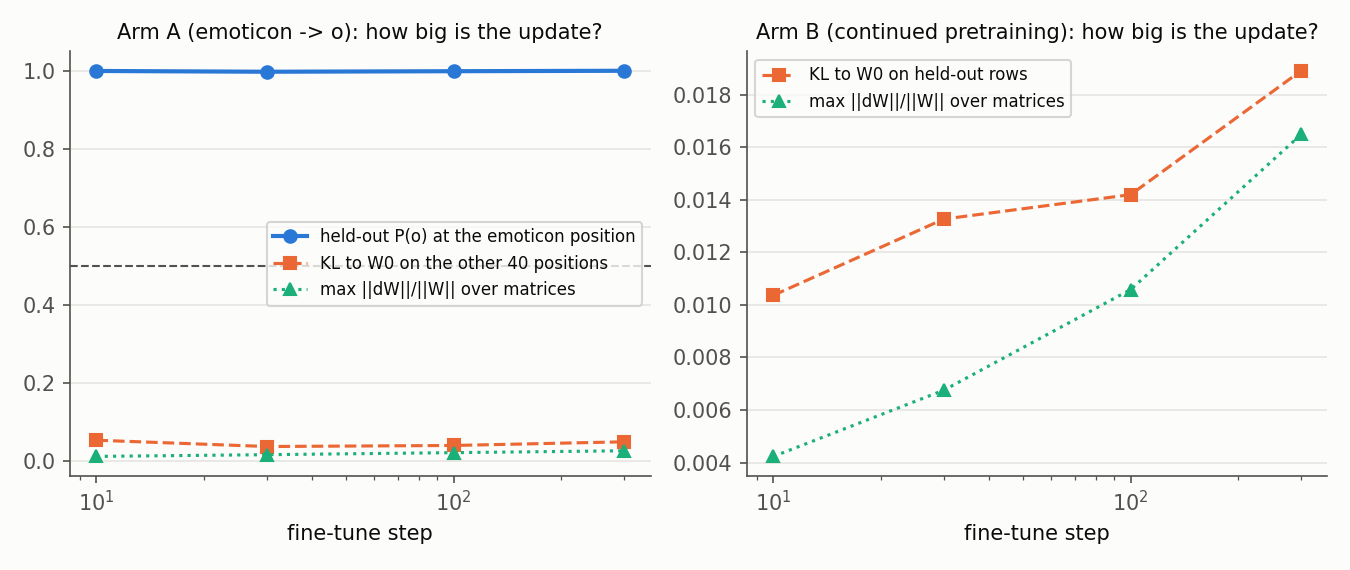

In [2]:
display(Image(F / 'finetune_curves.png'))

## Could it do it? Is the update in the span of the existing subcomponents? (measure 1)

No. The Frobenius fraction of δW on the alive subcomponents is 1.5 to 1.7 times that of a random direction of the same norm, not the predicted 10 times (prediction 2, first half: reversed). In absolute terms the fraction stays below 0.4%, but relative to a random direction, arm A's grows with training: 1.7×, 2.3×, 5.4× and 10.2× at steps 10, 30, 100 and 300. Arm B's falls from 1.8× to 1.4×. This is unexplained (review report).

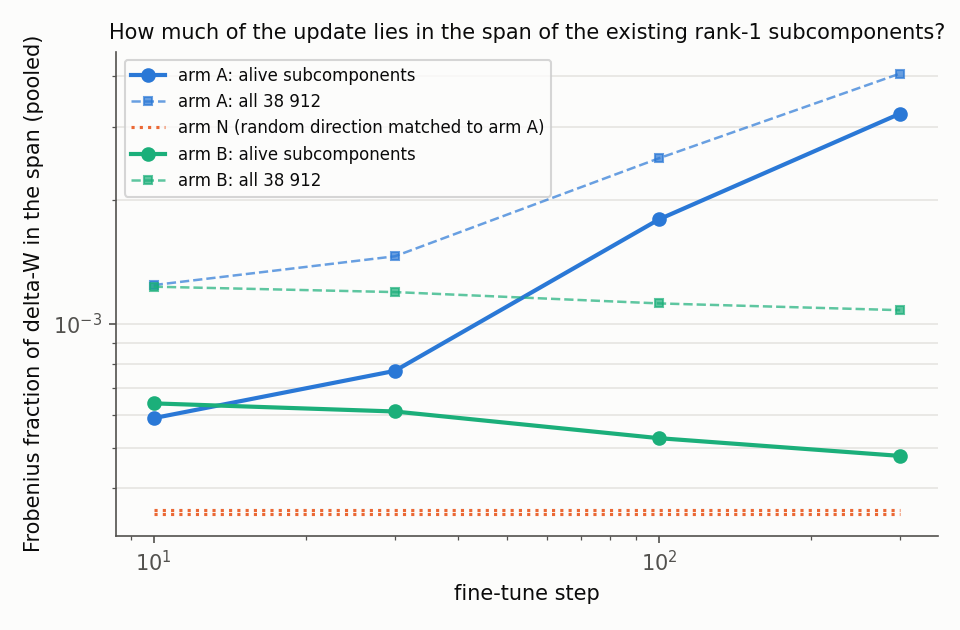

arm A alive/all/random: 0.00059 0.00124 [0.00034, 0.00034, 0.00035]
arm B alive/all/random: 0.00053 0.00112 [0.00035, 0.00035, 0.00036]


In [3]:
display(Image(F / 'frobenius_fraction.png'))
s = A['steps'][str(A['scored_checkpoint'])]; sb = B['steps'][str(B['scored_checkpoint'])]
print('arm A alive/all/random:', round(s['T0_frobenius']['fraction_alive_pooled'], 5), round(s['T0_frobenius']['fraction_all_pooled'], 5), [round(x, 5) for x in s['arm_N_fraction_alive_pooled']])
print('arm B alive/all/random:', round(sb['T0_frobenius']['fraction_alive_pooled'], 5), round(sb['T0_frobenius']['fraction_all_pooled'], 5), [round(x, 5) for x in sb['arm_N_fraction_alive_pooled']])

## Does it match the prediction? Functional capture against k, top-k versus random (measure 2)

Arm A: ten edited subcomponents reproduce the emoticon behaviour, and so do ten random ones (prediction 1a: margin 0.013, inside the null band; reversed). Only k = 3 separates them, by 0.16. Arm B: every fit is worse than doing nothing on held-out rows (prediction 2, second half: reversed); the fits did not converge (their training-set KL rose: Adam lr 1e-2 is too large for a 0.014-nat target), so this half is uninformative (review `reports/reviews/2026-10-14_review_round1-audit.md`).

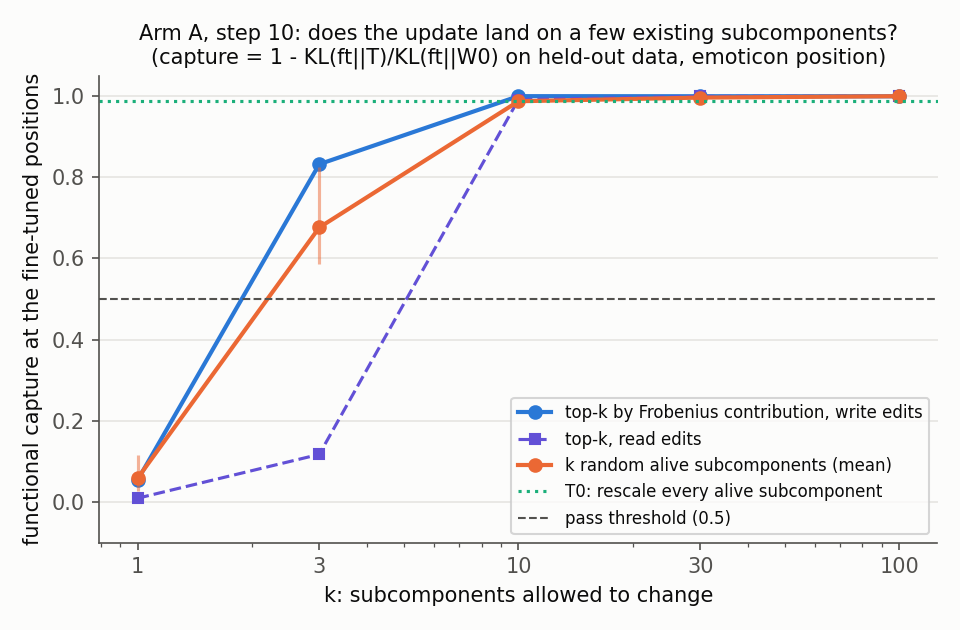

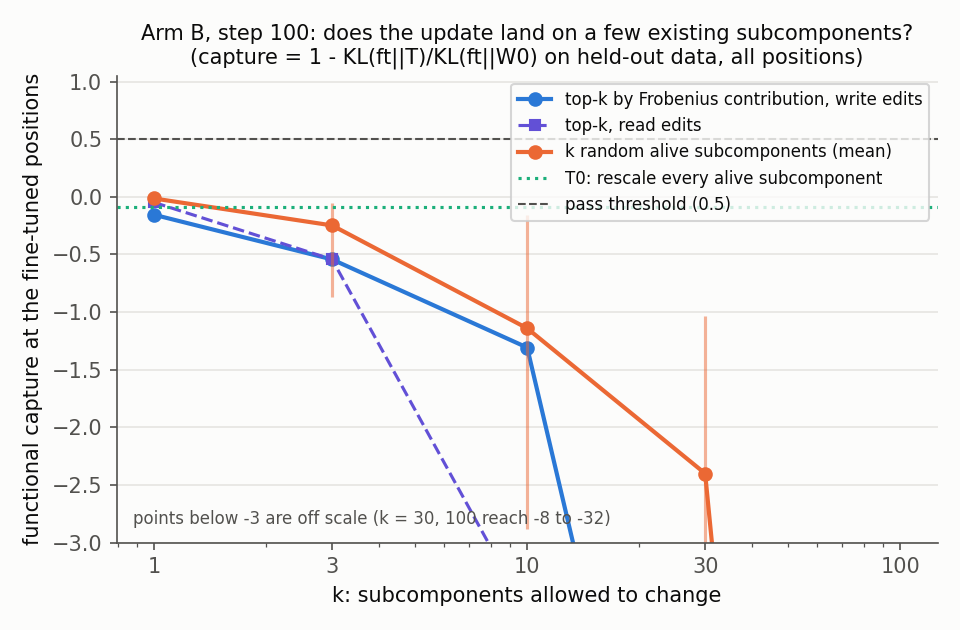

arm A k=  1: top 0.054  random [0.028, 0.064, 0.049, 0.035, 0.117]  read 0.009
arm A k=  3: top 0.832  random [0.61, 0.774, 0.825, 0.586, 0.587]  read 0.117
arm A k= 10: top 1.000  random [0.99, 0.978, 0.998, 0.987, 0.984]  read 0.991
arm A k= 30: top 1.000  random [0.999, 0.998, 0.998, 0.991, 0.995]  read 0.999
arm A k=100: top 0.999  random [1.0, 1.0, 1.0, 1.0, 1.0]  read 1.000


In [4]:
display(Image(F / 'capture_vs_k_armA.png')); display(Image(F / 'capture_vs_k_armB.png'))
for k in ('1', '3', '10', '30', '100'):
    r = s['T1'][k]
    print(f"arm A k={k:>3}: top {r['write']['primary']['capture']:.3f}  random {[round(x['primary']['capture'], 3) for x in r.get('random_write', [])]}  read {r.get('read', {}).get('primary', {}).get('capture', float('nan')):.3f}")

## Where did the update go? (measure 4, prediction 1b, held)

Among the alive subcomponents of `h.2.mlp.down_proj`, the paper's emoticon subcomponent 2359 ranks second by Frobenius contribution at step 10, with three siblings in the top eight; by step 30 the family has dispersed.

In [5]:
for st in sorted(A['steps'], key=int):
    print('step', st, A['steps'][st]['1b_location']['ranks'])

step 10 {'1672': 6, '2359': 2, '2623': 54, '3290': 63, '3327': 8, '3382': 5}
step 30 {'1672': 357, '2359': 354, '2623': 24, '3290': 6, '3327': 2, '3382': 16}
step 100 {'1672': 179, '2359': 23, '2623': 19, '3290': 11, '3327': 5, '3382': 8}
step 300 {'1672': 353, '2359': 41, '2623': 51, '3290': 32, '3327': 8, '3382': 5}


## Is the transported decomposition still faithful? (measure 3, prediction 3, held)

Stochastic ratios to the released decomposition on W0 are 0.94 to 1.02 everywhere. Adversarial ratios pass for the scored variants (1.43 for arm A, 1.05 for arm B); the null transport at arm A's step 10 reaches 2.4, driven by one of the two row blocks, and is 1.0 to 1.3 at later checkpoints.

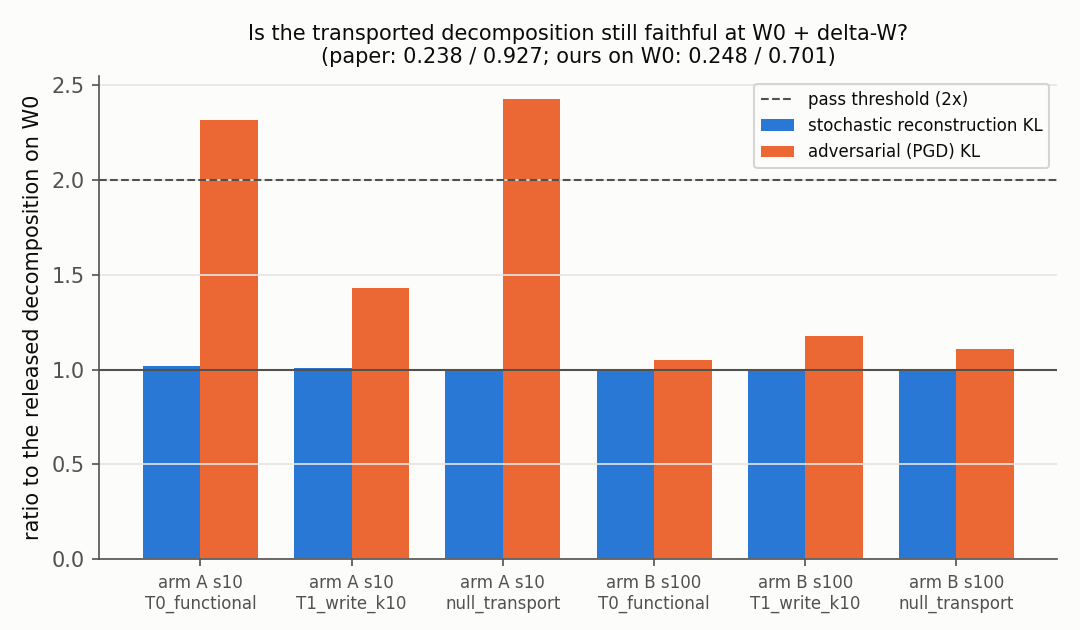

A 10 {'T0_functional': {'pgd_kl': 2.32, 'stochastic_kl': 1.02}, 'T1_write_k10': {'pgd_kl': 1.43, 'stochastic_kl': 1.01}, 'null_transport': {'pgd_kl': 2.43, 'stochastic_kl': 1.0}}
A 30 {'null_transport': {'pgd_kl': 1.02, 'stochastic_kl': 0.98}}
A 100 {'null_transport': {'pgd_kl': 1.14, 'stochastic_kl': 0.97}}
A 300 {'null_transport': {'pgd_kl': 1.27, 'stochastic_kl': 0.94}}
B 10 {'null_transport': {'pgd_kl': 1.07, 'stochastic_kl': 1.0}}
B 30 {'null_transport': {'pgd_kl': 1.09, 'stochastic_kl': 1.0}}
B 100 {'T0_functional': {'pgd_kl': 1.05, 'stochastic_kl': 1.0}, 'T1_write_k10': {'pgd_kl': 1.18, 'stochastic_kl': 1.0}, 'null_transport': {'pgd_kl': 1.11, 'stochastic_kl': 1.0}}
B 300 {'null_transport': {'pgd_kl': 1.1, 'stochastic_kl': 1.01}}


In [6]:
display(Image(F / 'faithfulness_ratios.png'))
for arm, f in (('A', fA), ('B', fB)):
    for st in sorted(f['steps'], key=int):
        print(arm, st, {v: {m: round(x, 2) for m, x in d['ratio_to_calibration'].items()} for v, d in f['steps'][st].items()})

## Summary

The literal projection of δW onto the subcomponent dictionary explains neither the parameters nor the behaviour of these updates. The behaviour of the emoticon fine-tune is easy to mimic with a few edited subcomponents, but the null used here (free write vectors on random subcomponents) is expressive enough to mimic it too, so round 2 needs a scale-only or constrained null and a functional selector. The decomposition does not break: faithfulness holds under every transport by the stochastic measure. Next steps are listed in `backlog.md` and go through `/design`.